In [1]:
import matplotlib.pyplot as plt
import os
import pandas as pd
from openpyxl.styles import Alignment, Border, Font, Side
from openpyxl.utils import get_column_letter
from openpyxl.workbook import Workbook
from PIL import Image

tables_folder = "./tables"
screenshots_folder = "./screenshots"

products = pd.read_excel("products.xlsx")

In [2]:
def create_table(df, columns, n_samples=10, seed=0):
    samples = df.sample(n=n_samples, random_state=seed)
    table = samples[columns].copy()
    return table

def save_table_to_csv(filename, df):
    filepath = f"{tables_folder}/{filename}"
    df.to_csv(filepath, sep=";", index=False, encoding="utf-8-sig")
    print(f"Таблица сохранена в {filepath}")

def save_table_to_excel(
    filename, df, columns_widths, center_alignment=False,
    custom_font=False, contrast_borders=False,
):
    wb = Workbook()
    ws = wb.active
    ws.append([])
    for _, row in df.iterrows():
        ws.append([""] + row.to_list())
    
    start_row = 2
    end_row = start_row + df.shape[0] - 1
    start_col = 2
    end_col = start_col + df.shape[1] - 1
    
    ws.column_dimensions["A"].width = 3
    for i, width in enumerate(columns_widths):
        ws.column_dimensions[get_column_letter(start_col + i)].width = width
    
    cell_alignment = Alignment(
        horizontal="center" if center_alignment else None,
        vertical="center", wrap_text=True,
    )
    cell_font = Font(name="GOST2304 Type B" if custom_font else "Calibri")
    if contrast_borders:
        cell_border = Side(style="medium")
    
    for row in ws.iter_rows(min_row=start_row, max_row=end_row, min_col=start_col, max_col=end_col):
        for cell in row:
            cell.alignment = cell_alignment
            cell.font = cell_font
            if contrast_borders:
                cell.border = Border(
                    left=cell_border, right=cell_border,
                    top=cell_border, bottom=cell_border,
                )
    
    filepath = f"{tables_folder}/{filename}"
    if os.path.exists(filepath):
        os.remove(filepath)
    
    wb.save(filepath)
    print(f"Таблица сохранена в {filepath}")

def show_image(image_path):
    print(f"Изображение: {image_path}")
    image = Image.open(image_path)
    plt.figure(figsize=(12, 12))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

In [3]:
table_columns_1 = ["name", "type", "retail_price"]
table_1 = create_table(df=products, n_samples=3, seed=0, columns=table_columns_1)
table_1.style.hide(axis="index")

name,type,retail_price
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
Клипса для крепления наклеек,Клипса,"95,00"
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"


In [4]:
save_table_to_csv(filename="table_1.csv", df=table_1)

columns_widths_1 = [30, 40, 10]

save_table_to_excel(
    filename="table_1_base.xlsx", df=table_1, columns_widths=columns_widths_1,
    center_alignment=False, custom_font=False, contrast_borders=False,
)
save_table_to_excel(
    filename="table_1_base_contrast.xlsx", df=table_1, columns_widths=columns_widths_1,
    center_alignment=False, custom_font=False, contrast_borders=True,
)
save_table_to_excel(
    filename="table_1_gost.xlsx", df=table_1, columns_widths=columns_widths_1,
    center_alignment=False, custom_font=True, contrast_borders=False,
)
save_table_to_excel(
    filename="table_1_gost_contrast.xlsx", df=table_1, columns_widths=columns_widths_1,
    center_alignment=False, custom_font=True, contrast_borders=True,
)

Таблица сохранена в ./tables/table_1.csv
Таблица сохранена в ./tables/table_1_base.xlsx
Таблица сохранена в ./tables/table_1_base_contrast.xlsx
Таблица сохранена в ./tables/table_1_gost.xlsx
Таблица сохранена в ./tables/table_1_gost_contrast.xlsx


Изображение: ./screenshots/table_1_base_160.png


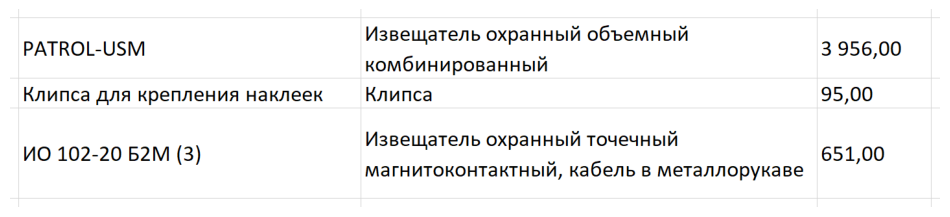

Изображение: ./screenshots/table_1_base_contrast_160.png


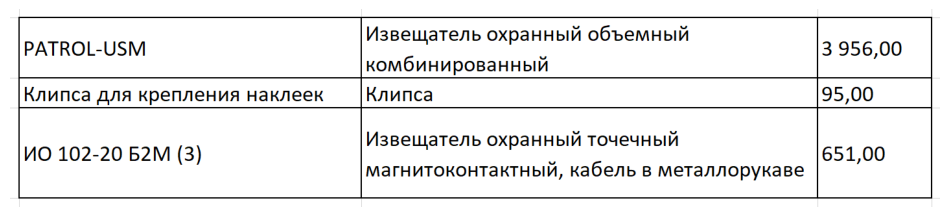

Изображение: ./screenshots/table_1_gost_160.png


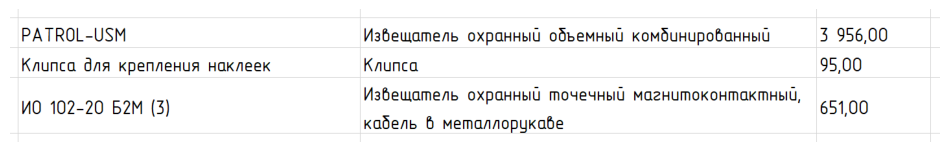

Изображение: ./screenshots/table_1_gost_contrast_160.png


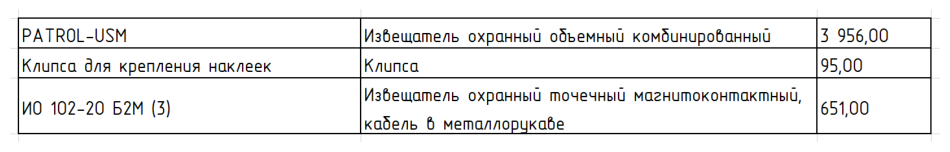

In [5]:
show_image(f"{screenshots_folder}/table_1_base_160.png")
show_image(f"{screenshots_folder}/table_1_base_contrast_160.png")
show_image(f"{screenshots_folder}/table_1_gost_160.png")
show_image(f"{screenshots_folder}/table_1_gost_contrast_160.png")

In [6]:
table_columns_2 = ["name", "type", "retail_price"]
table_2 = create_table(df=products, n_samples=20, seed=0, columns=table_columns_2)
table_2.style.hide(axis="index")

name,type,retail_price
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
Клипса для крепления наклеек,Клипса,"95,00"
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
ИД2-50Ш,Извещатель инфракрасный пассивный,"10 105,00"
СПЭК-1115М (ИО 209-32/2),Извещатель охранный оптико-электронный линейный,"41 800,00"
"ИО 102-26 исп.00 ""Аякс""",Извещатель охранный точечный магнитоконтактный,"429,34"
Пульсар 52,Извещатель пожарный дымовой оптико-электронный точечный,"13 622,00"
Мурена-01,Вибрационное средство обнаружения,"95 500,00"
Фотон-12 (ИО 409-17/1),Извещатель охранный объемный оптико-электронный,"1 024,00"
ИП 212-141 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"596,00"


In [7]:
table_2 = table_2.iloc[[0, 1, 2, 11, 12, 18]]
table_2.style.hide(axis="index")

name,type,retail_price
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
Клипса для крепления наклеек,Клипса,"95,00"
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00"
"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60"
AX-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00"


In [8]:
save_table_to_csv(filename="table_2.csv", df=table_2)

columns_widths_2 = [30, 40, 10]

save_table_to_excel(
    filename="table_2_base.xlsx", df=table_2, columns_widths=columns_widths_2,
    center_alignment=False, custom_font=False, contrast_borders=False,
)
save_table_to_excel(
    filename="table_2_base_contrast.xlsx", df=table_2, columns_widths=columns_widths_2,
    center_alignment=False, custom_font=False, contrast_borders=True,
)
save_table_to_excel(
    filename="table_2_gost.xlsx", df=table_2, columns_widths=columns_widths_2,
    center_alignment=False, custom_font=True, contrast_borders=False,
)
save_table_to_excel(
    filename="table_2_gost_contrast.xlsx", df=table_2, columns_widths=columns_widths_2,
    center_alignment=False, custom_font=True, contrast_borders=True,
)

Таблица сохранена в ./tables/table_2.csv
Таблица сохранена в ./tables/table_2_base.xlsx
Таблица сохранена в ./tables/table_2_base_contrast.xlsx
Таблица сохранена в ./tables/table_2_gost.xlsx
Таблица сохранена в ./tables/table_2_gost_contrast.xlsx


Изображение: ./screenshots/table_2_base_160.png


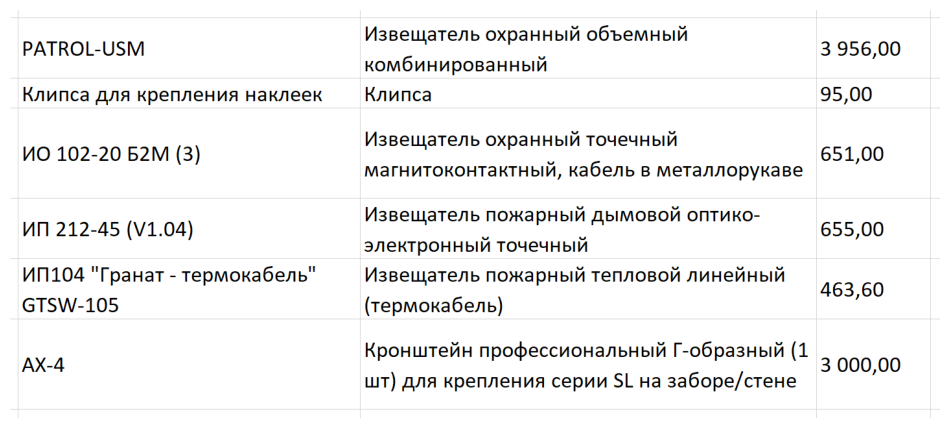

Изображение: ./screenshots/table_2_base_contrast_160.png


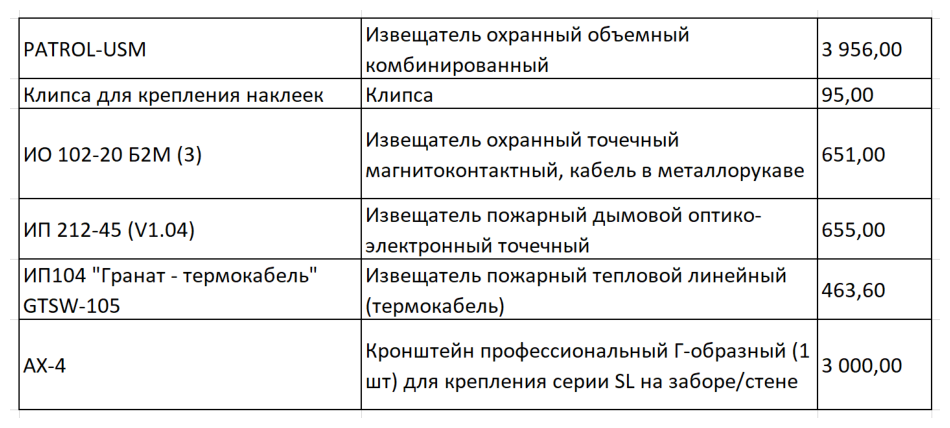

Изображение: ./screenshots/table_2_gost_160.png


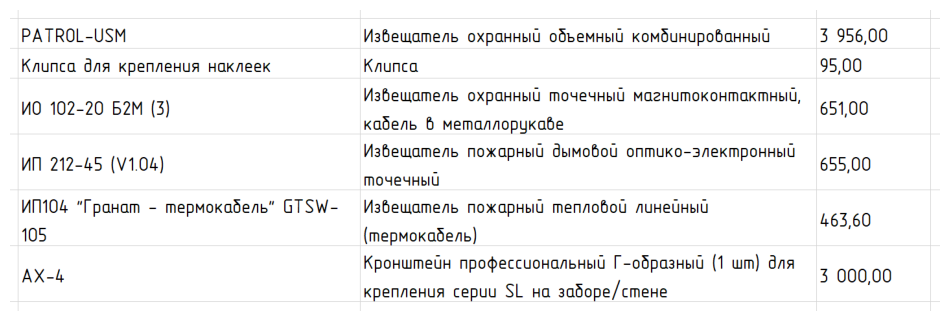

Изображение: ./screenshots/table_2_gost_contrast_160.png


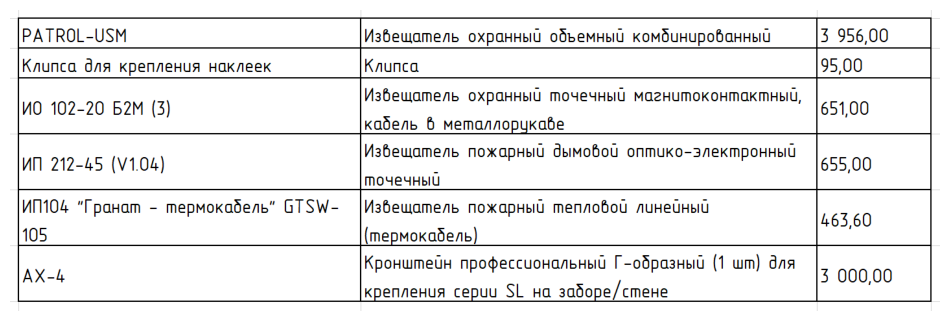

In [9]:
show_image(f"{screenshots_folder}/table_2_base_160.png")
show_image(f"{screenshots_folder}/table_2_base_contrast_160.png")
show_image(f"{screenshots_folder}/table_2_gost_160.png")
show_image(f"{screenshots_folder}/table_2_gost_contrast_160.png")

In [10]:
table_columns_3 = ["name", "type", "retail_price", "manufacturer", "article"]
table_3 = create_table(df=products, n_samples=20, seed=0, columns=table_columns_3)
table_3.style.hide(axis="index")

name,type,retail_price,manufacturer,article
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",nan
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,nan
ИД2-50Ш,Извещатель инфракрасный пассивный,"10 105,00",Полисервис,00003688
СПЭК-1115М (ИО 209-32/2),Извещатель охранный оптико-электронный линейный,"41 800,00",СПЭК,nan
"ИО 102-26 исп.00 ""Аякс""",Извещатель охранный точечный магнитоконтактный,"429,34",Магнито-Контакт,02-0020-0000
Пульсар 52,Извещатель пожарный дымовой оптико-электронный точечный,"13 622,00",КБ Прибор,nan
Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
Фотон-12 (ИО 409-17/1),Извещатель охранный объемный оптико-электронный,"1 024,00",Риэлта,nan
ИП 212-141 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"596,00",Рубеж,Rbz-338653


In [11]:
table_3 = table_3.iloc[[0, 1, 2, 11, 12, 18]]
table_3.style.hide(axis="index")

name,type,retail_price,manufacturer,article
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",nan
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,nan
ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
AX-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00",Optex,nan


In [12]:
save_table_to_csv(filename="table_3.csv", df=table_3)

columns_widths_3 = [24, 30, 10, 22, 12]

save_table_to_excel(
    filename="table_3_base.xlsx", df=table_3, columns_widths=columns_widths_3,
    center_alignment=False, custom_font=False, contrast_borders=False,
)
save_table_to_excel(
    filename="table_3_base_contrast.xlsx", df=table_3, columns_widths=columns_widths_3,
    center_alignment=False, custom_font=False, contrast_borders=True,
)
save_table_to_excel(
    filename="table_3_gost.xlsx", df=table_3, columns_widths=columns_widths_3,
    center_alignment=False, custom_font=True, contrast_borders=False,
)
save_table_to_excel(
    filename="table_3_gost_contrast.xlsx", df=table_3, columns_widths=columns_widths_3,
    center_alignment=False, custom_font=True, contrast_borders=True,
)

Таблица сохранена в ./tables/table_3.csv
Таблица сохранена в ./tables/table_3_base.xlsx
Таблица сохранена в ./tables/table_3_base_contrast.xlsx
Таблица сохранена в ./tables/table_3_gost.xlsx
Таблица сохранена в ./tables/table_3_gost_contrast.xlsx


Изображение: ./screenshots/table_3_base_160.png


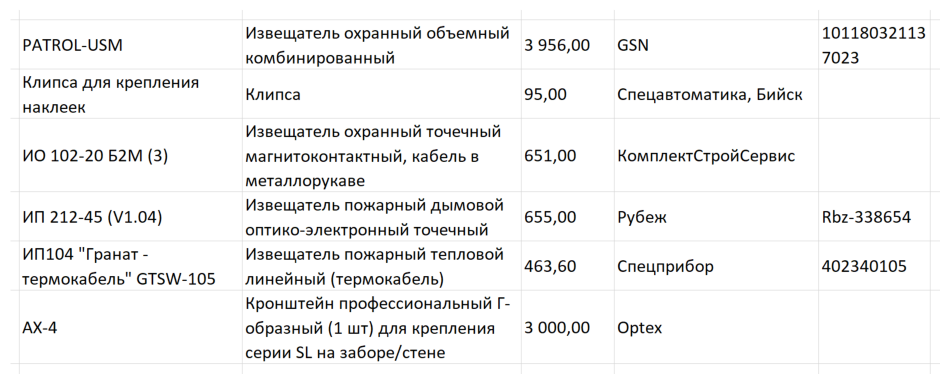

Изображение: ./screenshots/table_3_base_contrast_160.png


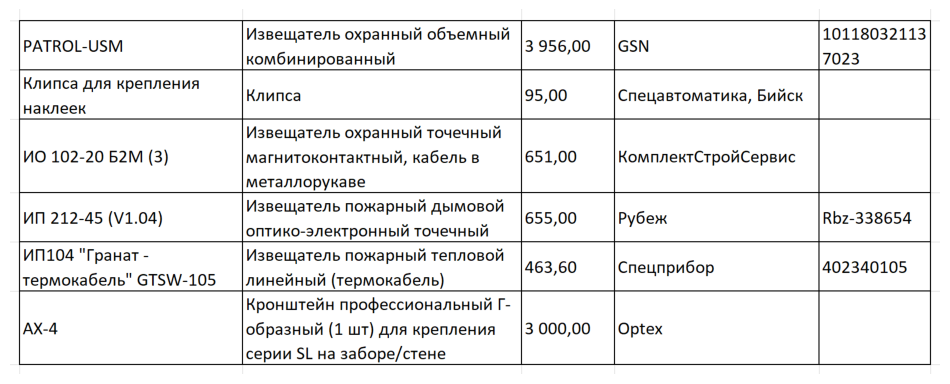

Изображение: ./screenshots/table_3_gost_160.png


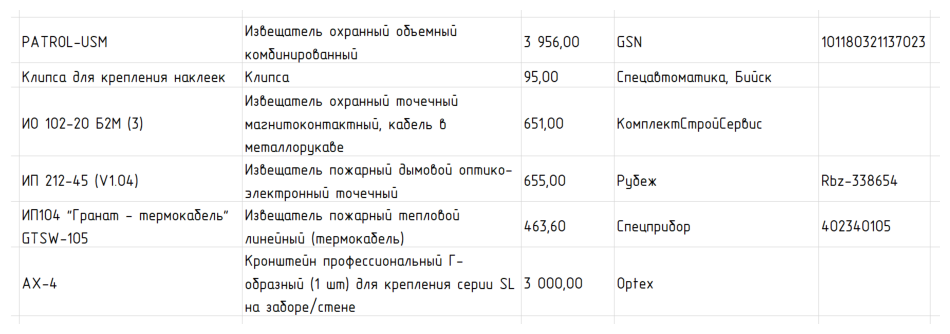

Изображение: ./screenshots/table_3_gost_contrast_160.png


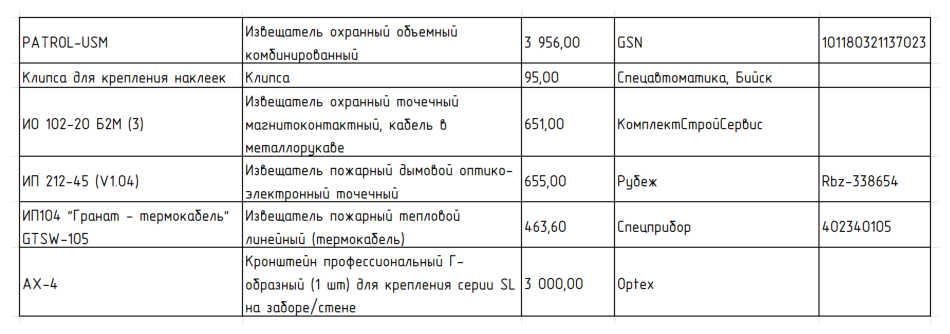

In [13]:
show_image(f"{screenshots_folder}/table_3_base_160.png")
show_image(f"{screenshots_folder}/table_3_base_contrast_160.png")
show_image(f"{screenshots_folder}/table_3_gost_160.png")
show_image(f"{screenshots_folder}/table_3_gost_contrast_160.png")

In [14]:
table_columns_4 = ["name", "type", "retail_price", "manufacturer", "article"]
table_4 = create_table(df=products, n_samples=30, seed=0, columns=table_columns_4)
table_4.style.hide(axis="index")

name,type,retail_price,manufacturer,article
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",nan
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,nan
ИД2-50Ш,Извещатель инфракрасный пассивный,"10 105,00",Полисервис,00003688
СПЭК-1115М (ИО 209-32/2),Извещатель охранный оптико-электронный линейный,"41 800,00",СПЭК,nan
"ИО 102-26 исп.00 ""Аякс""",Извещатель охранный точечный магнитоконтактный,"429,34",Магнито-Контакт,02-0020-0000
Пульсар 52,Извещатель пожарный дымовой оптико-электронный точечный,"13 622,00",КБ Прибор,nan
Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
Фотон-12 (ИО 409-17/1),Извещатель охранный объемный оптико-электронный,"1 024,00",Риэлта,nan
ИП 212-141 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"596,00",Рубеж,Rbz-338653


In [15]:
table_4 = table_4.iloc[[0, 1, 2, 7, 10, 11, 12, 18, 26, 28]]
table_4.style.hide(axis="index")

name,type,retail_price,manufacturer,article
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",nan
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,nan
Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
С2000-ИП-03,Извещатель пожарный тепловой максимально-дифференциальный адресно-аналоговый,"1 402,02",Болид,711-608-786
ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
AX-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00",Optex,nan
"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м, однопозиционный (ПТК ""ИВС"")",Извещатель пожарный дымовой оптико-электронный линейный оптический,"6 974,68","ПТК ""ИВС""",nan
"УДП 513-10 исп.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1 021,00",Рубеж,Rbz-122811


In [16]:
save_table_to_csv(filename="table_4.csv", df=table_4)

columns_widths_4 = [30, 40, 10, 22, 20]

save_table_to_excel(
    filename="table_4_base.xlsx", df=table_4, columns_widths=columns_widths_4,
    center_alignment=False, custom_font=False, contrast_borders=False,
)
save_table_to_excel(
    filename="table_4_base_contrast.xlsx", df=table_4, columns_widths=columns_widths_4,
    center_alignment=False, custom_font=False, contrast_borders=True,
)
save_table_to_excel(
    filename="table_4_gost.xlsx", df=table_4, columns_widths=columns_widths_4,
    center_alignment=False, custom_font=True, contrast_borders=False,
)
save_table_to_excel(
    filename="table_4_gost_contrast.xlsx", df=table_4, columns_widths=columns_widths_4,
    center_alignment=False, custom_font=True, contrast_borders=True,
)

Таблица сохранена в ./tables/table_4.csv
Таблица сохранена в ./tables/table_4_base.xlsx
Таблица сохранена в ./tables/table_4_base_contrast.xlsx
Таблица сохранена в ./tables/table_4_gost.xlsx
Таблица сохранена в ./tables/table_4_gost_contrast.xlsx


Изображение: ./screenshots/table_4_base_130.png


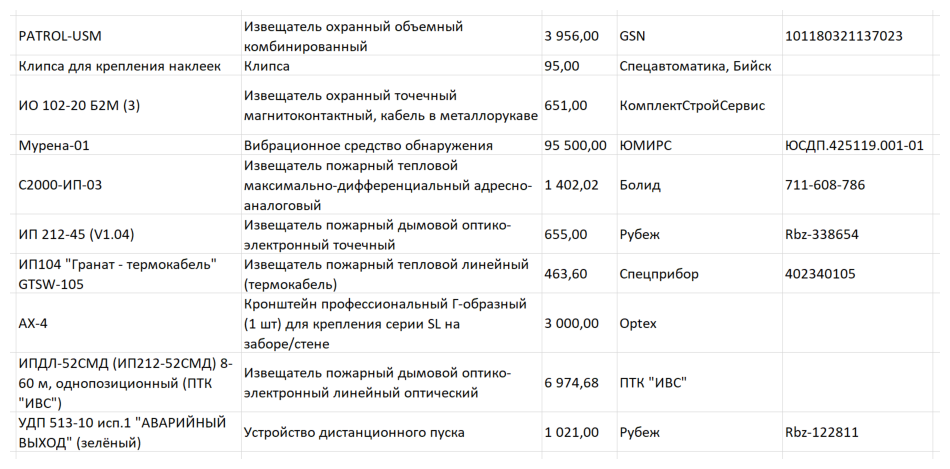

Изображение: ./screenshots/table_4_base_contrast_130.png


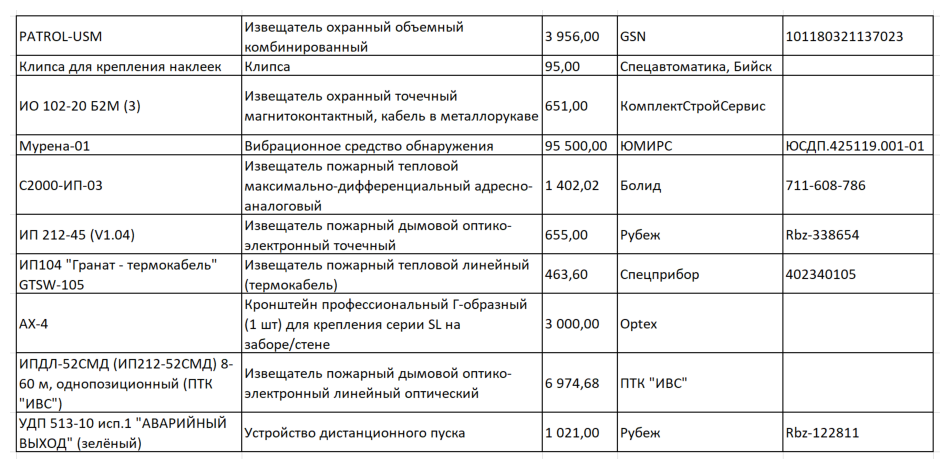

Изображение: ./screenshots/table_4_gost_130.png


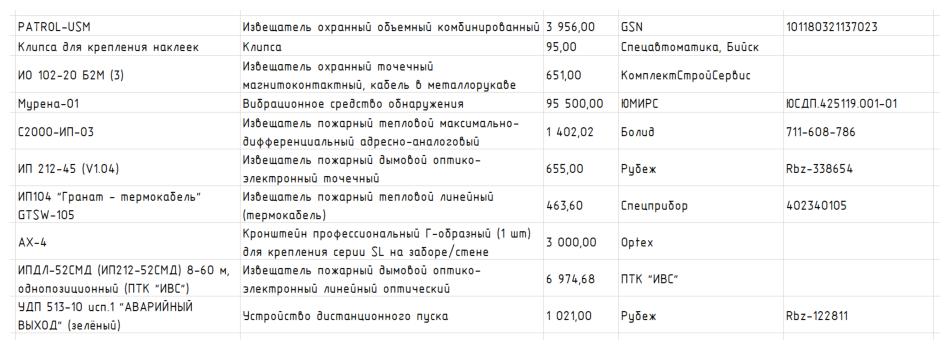

Изображение: ./screenshots/table_4_gost_contrast_130.png


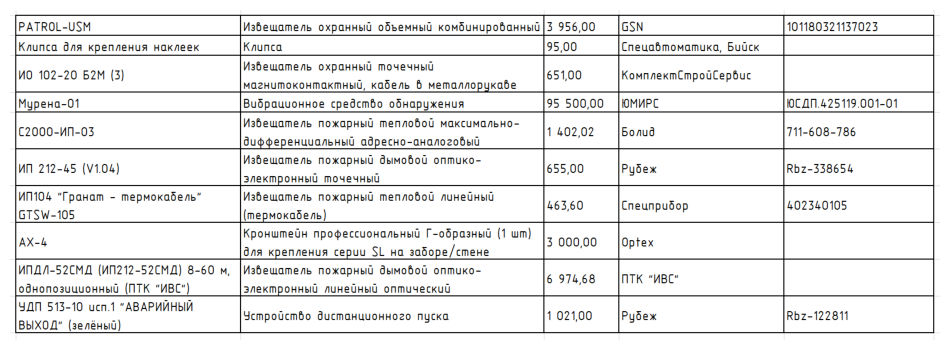

In [17]:
show_image(f"{screenshots_folder}/table_4_base_130.png")
show_image(f"{screenshots_folder}/table_4_base_contrast_130.png")
show_image(f"{screenshots_folder}/table_4_gost_130.png")
show_image(f"{screenshots_folder}/table_4_gost_contrast_130.png")

In [18]:
table_columns_5 = ["name", "type", "retail_price"]
table_5 = create_table(df=products, n_samples=3, seed=0, columns=table_columns_5)
table_5.style.hide(axis="index")

name,type,retail_price
PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
Клипса для крепления наклеек,Клипса,"95,00"
ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"


In [19]:
save_table_to_csv(filename="table_5.csv", df=table_5)

columns_widths_5 = [30, 40, 10]

save_table_to_excel(
    filename="table_5_base.xlsx", df=table_5, columns_widths=columns_widths_5,
    center_alignment=True, custom_font=False, contrast_borders=False,
)
save_table_to_excel(
    filename="table_5_base_contrast.xlsx", df=table_5, columns_widths=columns_widths_5,
    center_alignment=True, custom_font=False, contrast_borders=True,
)
save_table_to_excel(
    filename="table_5_gost.xlsx", df=table_5, columns_widths=columns_widths_5,
    center_alignment=True, custom_font=True, contrast_borders=False,
)
save_table_to_excel(
    filename="table_5_gost_contrast.xlsx", df=table_5, columns_widths=columns_widths_5,
    center_alignment=True, custom_font=True, contrast_borders=True,
)

Таблица сохранена в ./tables/table_5.csv
Таблица сохранена в ./tables/table_5_base.xlsx
Таблица сохранена в ./tables/table_5_base_contrast.xlsx
Таблица сохранена в ./tables/table_5_gost.xlsx
Таблица сохранена в ./tables/table_5_gost_contrast.xlsx


Изображение: ./screenshots/table_5_base_130.png


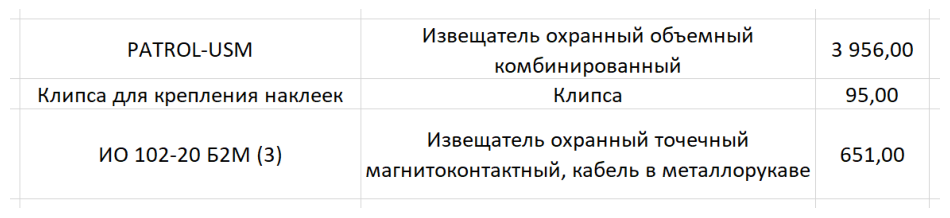

Изображение: ./screenshots/table_5_base_contrast_130.png


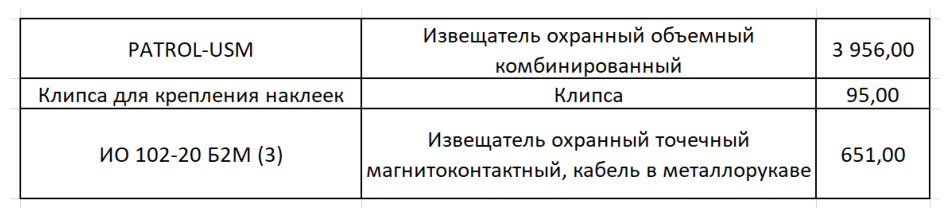

Изображение: ./screenshots/table_5_gost_130.png


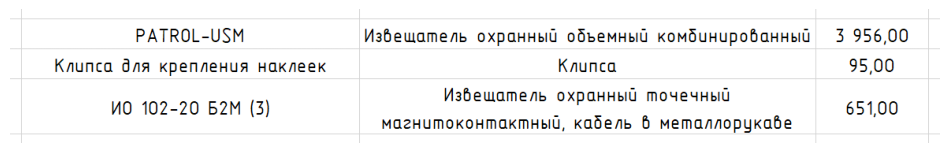

Изображение: ./screenshots/table_5_gost_contrast_130.png


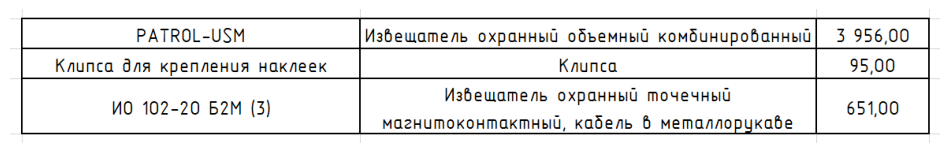

In [20]:
show_image(f"{screenshots_folder}/table_5_base_130.png")
show_image(f"{screenshots_folder}/table_5_base_contrast_130.png")
show_image(f"{screenshots_folder}/table_5_gost_130.png")
show_image(f"{screenshots_folder}/table_5_gost_contrast_130.png")